In [1]:
from google.colab import files

uploaded = files.upload()

Saving electricityloaddiagrams20112014.zip to electricityloaddiagrams20112014.zip


In [2]:
import zipfile
import pandas as pd
import os

zip_path = "electricityloaddiagrams20112014.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files in archive:")
    print(zip_ref.namelist())
    zip_ref.extractall("electricity_data")

file_path = "electricity_data/LD2011_2014.txt"

df = pd.read_csv(file_path, sep=";", decimal=",", parse_dates=[0])

print("\nDataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

Files in archive:
['LD2011_2014.txt', '__MACOSX/', '__MACOSX/._LD2011_2014.txt']

Dataset shape: (140256, 371)

First 5 rows:


,Unnamed: 0,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
0,2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Column names:
['Unnamed: 0', 'MT_001', 'MT_002', 'MT_003', 'MT_004', 'MT_005', 'MT_006', 'MT_007', 'MT_008', 'MT_009', 'MT_010', 'MT_011', 'MT_012', 'MT_013', 'MT_014', 'MT_015', 'MT_016', 'MT_017', 'MT_018', 'MT_019', 'MT_020', 'MT_021', 'MT_022', 'MT_023', 'MT_024', 'MT_025', 'MT_026', 'MT_027', 'MT_028', 'MT_029', 'MT_030', 'MT_031', 'MT_032', 'MT_033', 'MT_034', 'MT_035', 'MT_036', 'MT_037', 'MT_038', 'MT_039', 'MT_040', 'MT_041', 'MT_042', 'MT_043', 'MT_044', 'MT_045', 'MT_046', 'MT_047', 'MT_048', 'MT_049', 'MT_050', 'MT_051', 'MT_052', 'MT_053', 'MT_054', 'MT_055', 'MT_056', 'MT_057', 'MT_058', 'MT_059', 'MT_060', 'MT_061', 'MT_062', 'MT_063', 'MT_064', 'MT_065', 'MT_066', 'MT_067', 'MT_068', 'MT_069', 'MT_070', 'MT_071', 'MT_072', 'MT_073', 'MT_074', 'MT_075', 'MT_076', 'MT_077', 'MT_078', 'MT_079', 'MT_080', 'MT_081', 'MT_082', 'MT_083', 'MT_084', 'MT_085', 'MT_086', 'MT_087', 'MT_088', 'MT_089', 'MT_090', 'MT_091', 'MT_092', 'MT_093', 'MT_094', 'MT_095', 'MT_096', 'MT_097', 

In [7]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PINK_DARK = "#9D174D"
PINK_MAIN = "#DB2777"
PINK_MEDIUM = "#EC4899"
PINK_LIGHT = "#F9A8D4"
PINK_PALE = "#FCE7F3"

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "font.family": "DejaVu Sans"
})

os.makedirs("figures", exist_ok=True)

print("Libraries imported successfully.")
print("Pink theme configured.")

Libraries imported successfully.
Pink theme configured.


In [8]:
df = df.rename(columns={df.columns[0]: "Timestamp"})

df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)

client_columns = [c for c in df.columns if c.startswith("MT_")]

print("Dataset shape:", df.shape)
print("Number of clients:", len(client_columns))
print("Start date:", df["Timestamp"].min())
print("End date:", df["Timestamp"].max())

print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())

print("\nTime intervals:")
print(df["Timestamp"].diff().value_counts().head())

Dataset shape: (140256, 371)
Number of clients: 370
Start date: 2011-01-01 00:15:00
End date: 2015-01-01 00:00:00

Missing values: 0
Duplicate rows: 0
Duplicate timestamps: 0

Time intervals:
Timestamp
0 days 00:15:00    140255
Name: count, dtype: int64


In [9]:
train_end = int(len(df) * 0.70)
train_data = df.iloc[:train_end]

client_stats = pd.DataFrame({
    "Client": client_columns,
    "Mean": train_data[client_columns].mean().values,
    "Std": train_data[client_columns].std().values,
    "Zero_Ratio": (train_data[client_columns] == 0).mean().values
})

client_stats["CV"] = (
    client_stats["Std"] /
    client_stats["Mean"].replace(0, np.nan)
)

eligible = client_stats[
    (client_stats["Zero_Ratio"] < 0.20) &
    (client_stats["CV"].notna())
].sort_values("CV").reset_index(drop=True)

if len(eligible) < 3:
    raise ValueError("Not enough eligible clients.")

selected_clients = {
    "Stable": eligible.iloc[0]["Client"],
    "Moderate": eligible.iloc[len(eligible)//2]["Client"],
    "Variable": eligible.iloc[-1]["Client"]
}

print("Selected clients:\n")

for profile, client in selected_clients.items():
    row = eligible[eligible["Client"] == client].iloc[0]
    print(f"{profile}: {client} | CV = {row['CV']:.3f}")

Selected clients:

Stable: MT_163 | CV = 0.160
Moderate: MT_225 | CV = 0.319
Variable: MT_187 | CV = 1.342


In [10]:
WINDOW = 96
HORIZON = 4

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

datasets = {}

for profile, client in selected_clients.items():

    values = df[client].values.reshape(-1, 1)

    scaler = MinMaxScaler()
    scaler.fit(values[:train_end])

    scaled_values = scaler.transform(values).flatten()

    datasets[profile] = {
        "client": client,
        "values": values.flatten(),
        "scaled": scaled_values,
        "scaler": scaler
    }

print("Train observations:", train_end)
print("Validation observations:", val_end - train_end)
print("Test observations:", n - val_end)

Train observations: 98179
Validation observations: 21038
Test observations: 21039


In [11]:
def create_sequences(data, window=96, horizon=4):
    X, y, target_indices = [], [], []

    for t in range(window - 1, len(data) - horizon):
        X.append(data[t-window+1:t+1])
        y.append(data[t+horizon])
        target_indices.append(t+horizon)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(target_indices)
    )

for profile, data in datasets.items():

    X, y, indices = create_sequences(
        data["scaled"],
        WINDOW,
        HORIZON
    )

    train_mask = indices < train_end
    val_mask = (indices >= train_end) & (indices < val_end)
    test_mask = indices >= val_end

    data["X_train"] = X[train_mask].reshape(-1, WINDOW, 1)
    data["y_train"] = y[train_mask]

    data["X_val"] = X[val_mask].reshape(-1, WINDOW, 1)
    data["y_val"] = y[val_mask]

    data["X_test"] = X[test_mask].reshape(-1, WINDOW, 1)
    data["y_test"] = y[test_mask]

    data["test_indices"] = indices[test_mask]

    print(f"\n{profile} ({data['client']})")
    print("Train:", data["X_train"].shape)
    print("Validation:", data["X_val"].shape)
    print("Test:", data["X_test"].shape)


Stable (MT_163)
Train: (98080, 96, 1)
Validation: (21038, 96, 1)
Test: (21039, 96, 1)

Moderate (MT_225)
Train: (98080, 96, 1)
Validation: (21038, 96, 1)
Test: (21039, 96, 1)

Variable (MT_187)
Train: (98080, 96, 1)
Validation: (21038, 96, 1)
Test: (21039, 96, 1)


In [12]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    positive_mask = y_true > 0

    mape = (
        np.mean(
            np.abs(
                (y_true[positive_mask] - y_pred[positive_mask])
                / y_true[positive_mask]
            )
        ) * 100
        if positive_mask.any()
        else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

print("Evaluation function ready.")

Evaluation function ready.


In [13]:
baseline_results = []
predictions = {}

for profile, data in datasets.items():

    client = data["client"]
    scaler = data["scaler"]

    y_true = scaler.inverse_transform(
        data["y_test"].reshape(-1, 1)
    ).flatten()

    # Persistence: latest observed value
    persistence_scaled = data["X_test"][:, -1, 0]

    persistence_pred = scaler.inverse_transform(
        persistence_scaled.reshape(-1, 1)
    ).flatten()

    # Seasonal naive: same time on previous day
    seasonal_scaled = data["X_test"][:, 3, 0]

    seasonal_pred = scaler.inverse_transform(
        seasonal_scaled.reshape(-1, 1)
    ).flatten()

    predictions[profile] = {
        "Actual": y_true,
        "Persistence": persistence_pred,
        "Seasonal Naive": seasonal_pred
    }

    for model_name, y_pred in [
        ("Persistence", persistence_pred),
        ("Seasonal Naive", seasonal_pred)
    ]:

        metrics = evaluate_model(y_true, y_pred)

        baseline_results.append({
            "Profile": profile,
            "Client": client,
            "Model": model_name,
            **metrics
        })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(3))

,Profile,Client,Model,MAE,RMSE,MAPE (%)
0,Stable,MT_163,Persistence,185.299,247.603,7.601
1,Stable,MT_163,Seasonal Naive,265.090,372.634,10.930
2,Moderate,MT_225,Persistence,25.457,37.314,9.387
3,Moderate,MT_225,Seasonal Naive,15.922,23.360,5.850
4,Variable,MT_187,Persistence,10.423,14.476,12.240
5,Variable,MT_187,Seasonal Naive,8.080,11.439,8.881


In [14]:
import time

LAGS = [0, 1, 3, 7, 15, 31, 63, 95]

def make_gb_features(X):
    return X[:, :, 0][:, [95 - lag for lag in LAGS]]

for profile, data in datasets.items():

    start_time = time.time()

    X_train_gb = make_gb_features(data["X_train"])
    X_val_gb = make_gb_features(data["X_val"])
    X_test_gb = make_gb_features(data["X_test"])

    # Subsample training data for computational efficiency
    rng = np.random.default_rng(SEED)
    sample_size = min(30000, len(X_train_gb))

    sample_idx = np.sort(
        rng.choice(
            len(X_train_gb),
            size=sample_size,
            replace=False
        )
    )

    gb_model = HistGradientBoostingRegressor(
        max_iter=150,
        max_depth=5,
        learning_rate=0.05,
        random_state=SEED
    )

    gb_model.fit(
        X_train_gb[sample_idx],
        data["y_train"][sample_idx]
    )

    gb_pred_scaled = gb_model.predict(X_test_gb)

    gb_pred = data["scaler"].inverse_transform(
        gb_pred_scaled.reshape(-1, 1)
    ).flatten()

    y_true = predictions[profile]["Actual"]

    metrics = evaluate_model(y_true, gb_pred)

    predictions[profile]["Gradient Boosting"] = gb_pred

    baseline_results.append({
        "Profile": profile,
        "Client": data["client"],
        "Model": "Gradient Boosting",
        **metrics
    })

    print(
        f"{profile} ({data['client']}): "
        f"completed in {time.time() - start_time:.1f} seconds"
    )

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(3))

Stable (MT_163): completed in 2.5 seconds
Moderate (MT_225): completed in 2.4 seconds
Variable (MT_187): completed in 3.5 seconds


,Profile,Client,Model,MAE,RMSE,MAPE (%)
0,Stable,MT_163,Persistence,185.299,247.603,7.601
1,Stable,MT_163,Seasonal Naive,265.090,372.634,10.930
2,Moderate,MT_225,Persistence,25.457,37.314,9.387
3,Moderate,MT_225,Seasonal Naive,15.922,23.360,5.850
4,Variable,MT_187,Persistence,10.423,14.476,12.240
5,Variable,MT_187,Seasonal Naive,8.080,11.439,8.881
6,Stable,MT_163,Gradient Boosting,151.499,202.487,6.147
7,Moderate,MT_225,Gradient Boosting,24.246,31.609,9.200
8,Variable,MT_187,Gradient Boosting,8.305,10.988,9.971


In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


In [17]:
lstm_results = []
training_histories = {}
lstm_models = {}
training_times = {}

for profile, data in datasets.items():

    print(f"\nTraining LSTM for {profile} ({data['client']})")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = Sequential([
        Input(shape=(WINDOW, 1)),
        LSTM(64),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        data["X_train"],
        data["y_train"],
        validation_data=(
            data["X_val"],
            data["y_val"]
        ),
        epochs=20,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=1,
        shuffle=False
    )

    training_time = time.time() - start_time

    pred_scaled = model.predict(
        data["X_test"],
        verbose=0
    )

    pred = data["scaler"].inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).flatten()

    y_true = predictions[profile]["Actual"]

    metrics = evaluate_model(y_true, pred)

    lstm_results.append({
        "Profile": profile,
        "Client": data["client"],
        "Model": "LSTM",
        **metrics
    })

    predictions[profile]["LSTM"] = pred
    training_histories[profile] = history.history
    lstm_models[profile] = model
    training_times[profile] = training_time

    print(f"\n{profile} completed.")
    print(f"Training time: {training_time:.1f} seconds")
    print(f"MAE: {metrics['MAE']:.3f}")
    print(f"RMSE: {metrics['RMSE']:.3f}")
    print(f"MAPE: {metrics['MAPE (%)']:.3f}%")


Training LSTM for Stable (MT_163)
Epoch 1/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 121s 38ms/step - loss: 0.0030 - val_loss: 0.0017
Epoch 2/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 120s 39ms/step - loss: 0.0021 - val_loss: 0.0015
Epoch 3/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 117s 38ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 4/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 145s 39ms/step - loss: 0.0020 - val_loss: 0.0015
Epoch 5/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 118s 38ms/step - loss: 0.0019 - val_loss: 0.0015
Epoch 6/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 144s 39ms/step - loss: 0.0018 - val_loss: 0.0014
Epoch 7/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 141s 39ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 8/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 120s 39ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 9/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 119s 39ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 10/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 141s 38ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 11/20
3065/3065 ━━━━━━━━━━━━━━━━━━━━ 119s 39ms/s

In [18]:
lstm_df = pd.DataFrame(lstm_results)

results_df = pd.concat(
    [baseline_df, lstm_df],
    ignore_index=True
)

results_df = results_df.sort_values(
    ["Profile", "Model"]
).reset_index(drop=True)

display(results_df.round(3))

,Profile,Client,Model,MAE,RMSE,MAPE (%)
0,Moderate,MT_225,Gradient Boosting,24.246,31.609,9.200
1,Moderate,MT_225,LSTM,25.907,32.175,9.076
2,Moderate,MT_225,Persistence,25.457,37.314,9.387
3,Moderate,MT_225,Seasonal Naive,15.922,23.360,5.850
4,Stable,MT_163,Gradient Boosting,151.499,202.487,6.147
5,Stable,MT_163,LSTM,155.611,207.481,6.254
6,Stable,MT_163,Persistence,185.299,247.603,7.601
7,Stable,MT_163,Seasonal Naive,265.090,372.634,10.930
8,Variable,MT_187,Gradient Boosting,8.305,10.988,9.971
9,Variable,MT_187,LSTM,9.699,11.982,13.207


In [19]:
from scipy.stats import norm

def block_bootstrap_ci(y_true, y_pred, n_boot=500, block_size=96):
    rng = np.random.default_rng(SEED)
    errors = np.abs(y_true - y_pred)
    n = len(errors)
    n_blocks = int(np.ceil(n / block_size))
    scores = []

    for _ in range(n_boot):
        starts = rng.integers(0, n - block_size + 1, size=n_blocks)
        indices = np.concatenate([
            np.arange(s, s + block_size) for s in starts
        ])[:n]
        scores.append(errors[indices].mean())

    return np.percentile(scores, [2.5, 97.5])

def diebold_mariano_test(y_true, pred_1, pred_2, horizon=4):
    d = (y_true - pred_1) ** 2 - (y_true - pred_2) ** 2
    n = len(d)
    d_mean = d.mean()
    gamma_0 = np.mean((d - d_mean) ** 2)
    variance = gamma_0

    for lag in range(1, horizon):
        gamma = np.mean(
            (d[lag:] - d_mean) * (d[:-lag] - d_mean)
        )
        variance += 2 * (1 - lag / horizon) * gamma

    if variance <= 0:
        return np.nan, np.nan

    statistic = d_mean / np.sqrt(variance / n)
    p_value = 2 * norm.sf(abs(statistic))

    return statistic, p_value

statistical_results = []

for profile, preds in predictions.items():
    y_true = preds["Actual"]
    lstm_pred = preds["LSTM"]

    ci_low, ci_high = block_bootstrap_ci(y_true, lstm_pred)

    for baseline in ["Persistence", "Seasonal Naive", "Gradient Boosting"]:
        dm_stat, p_value = diebold_mariano_test(
            y_true, lstm_pred, preds[baseline]
        )

        statistical_results.append({
            "Profile": profile,
            "Baseline": baseline,
            "LSTM MAE CI Lower": ci_low,
            "LSTM MAE CI Upper": ci_high,
            "DM Statistic": dm_stat,
            "p-value": p_value
        })

statistical_df = pd.DataFrame(statistical_results)
display(statistical_df.round(4))

,Profile,Baseline,LSTM MAE CI Lower,LSTM MAE CI Upper,DM Statistic,p-value
0,Stable,Persistence,149.3779,161.9714,-21.3315,0.0000
1,Stable,Seasonal Naive,149.3779,161.9714,-30.1709,0.0000
2,Stable,Gradient Boosting,149.3779,161.9714,4.9162,0.0000
3,Moderate,Persistence,24.8942,26.7861,-12.5255,0.0000
4,Moderate,Seasonal Naive,24.8942,26.7861,19.2412,0.0000
5,Moderate,Gradient Boosting,24.8942,26.7861,1.8926,0.0584
6,Variable,Persistence,9.4769,9.8571,-13.6383,0.0000
7,Variable,Seasonal Naive,9.4769,9.8571,3.0282,0.0025
8,Variable,Gradient Boosting,9.4769,9.8571,10.9327,0.0000


In [20]:
analysis_results = []

for profile, preds in predictions.items():
    actual = preds["Actual"]
    forecast = preds["LSTM"]

    errors = actual - forecast
    abs_errors = np.abs(errors)

    analysis_results.append({
        "Profile": profile,
        "Client": datasets[profile]["client"],
        "Mean Error": errors.mean(),
        "Median Absolute Error": np.median(abs_errors),
        "90th Percentile Error": np.percentile(abs_errors, 90),
        "Maximum Absolute Error": abs_errors.max(),
        "Overprediction (%)": (errors < 0).mean() * 100,
        "Underprediction (%)": (errors > 0).mean() * 100
    })

error_analysis_df = pd.DataFrame(analysis_results)

display(error_analysis_df.round(3))

,Profile,Client,Mean Error,Median Absolute Error,90th Percentile Error,Maximum Absolute Error,Overprediction (%),Underprediction (%)
0,Stable,MT_163,11.783,119.112999,339.083008,2407.949951,50.335,49.665
1,Moderate,MT_225,0.725,22.731001,51.040001,214.934006,52.887,47.113
2,Variable,MT_187,-4.654,8.579000,18.809000,60.742001,68.055,31.945


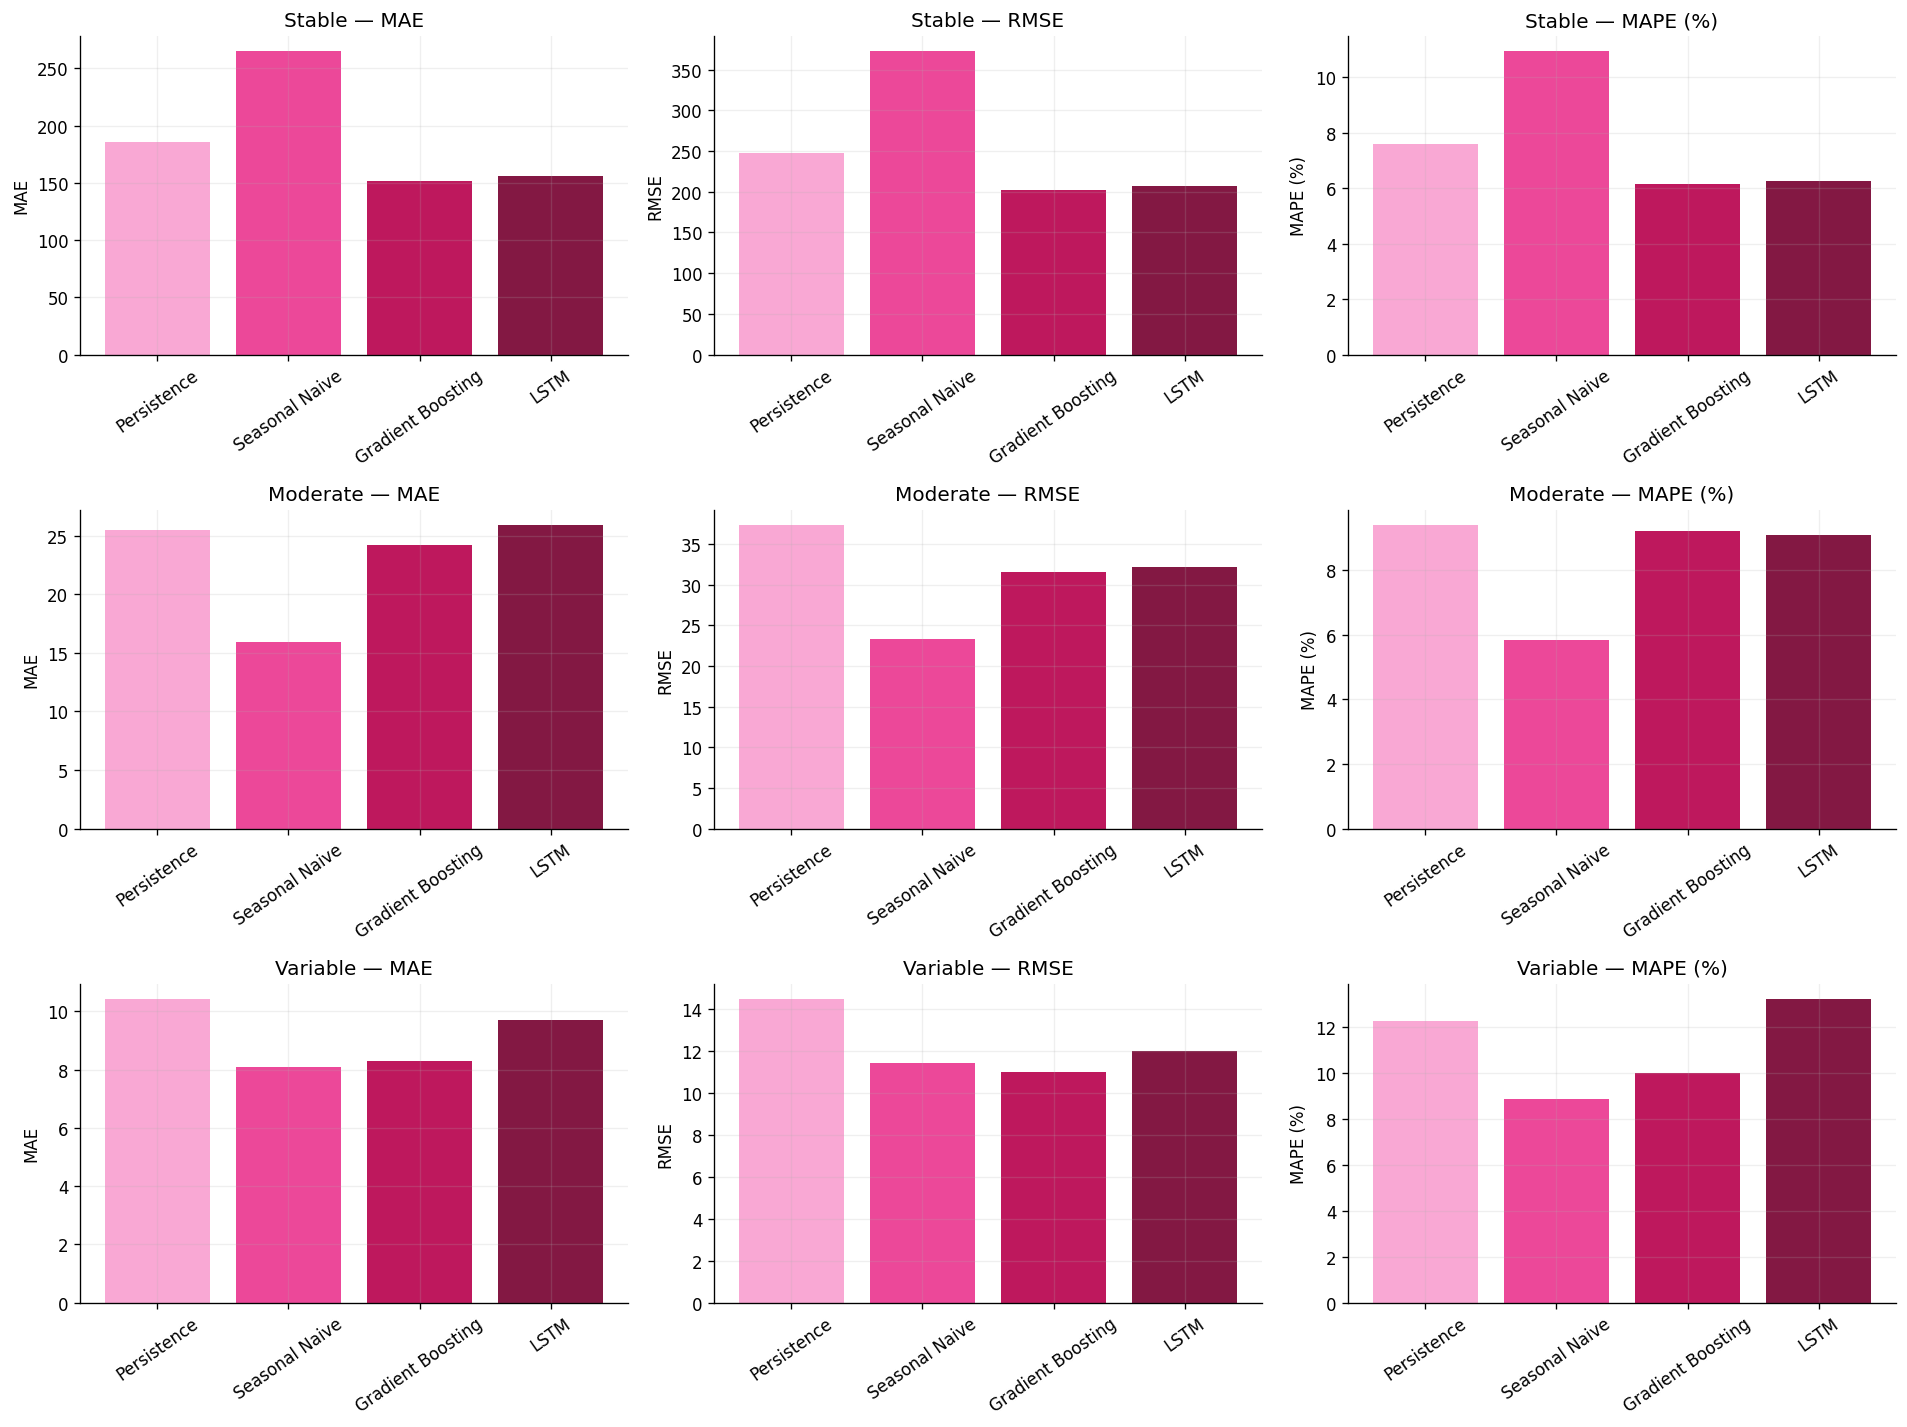

In [21]:
import matplotlib.pyplot as plt

models = ["Persistence", "Seasonal Naive", "Gradient Boosting", "LSTM"]
colors = ["#F9A8D4", "#EC4899", "#BE185D", "#831843"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for i, profile in enumerate(["Stable", "Moderate", "Variable"]):
    subset = results_df[results_df["Profile"] == profile]
    subset = subset.set_index("Model").loc[models]

    for j, metric in enumerate(["MAE", "RMSE", "MAPE (%)"]):
        ax = axes[i, j]
        ax.bar(models, subset[metric], color=colors)
        ax.set_title(f"{profile} — {metric}")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig("model_comparison.pdf", bbox_inches="tight")
plt.show()

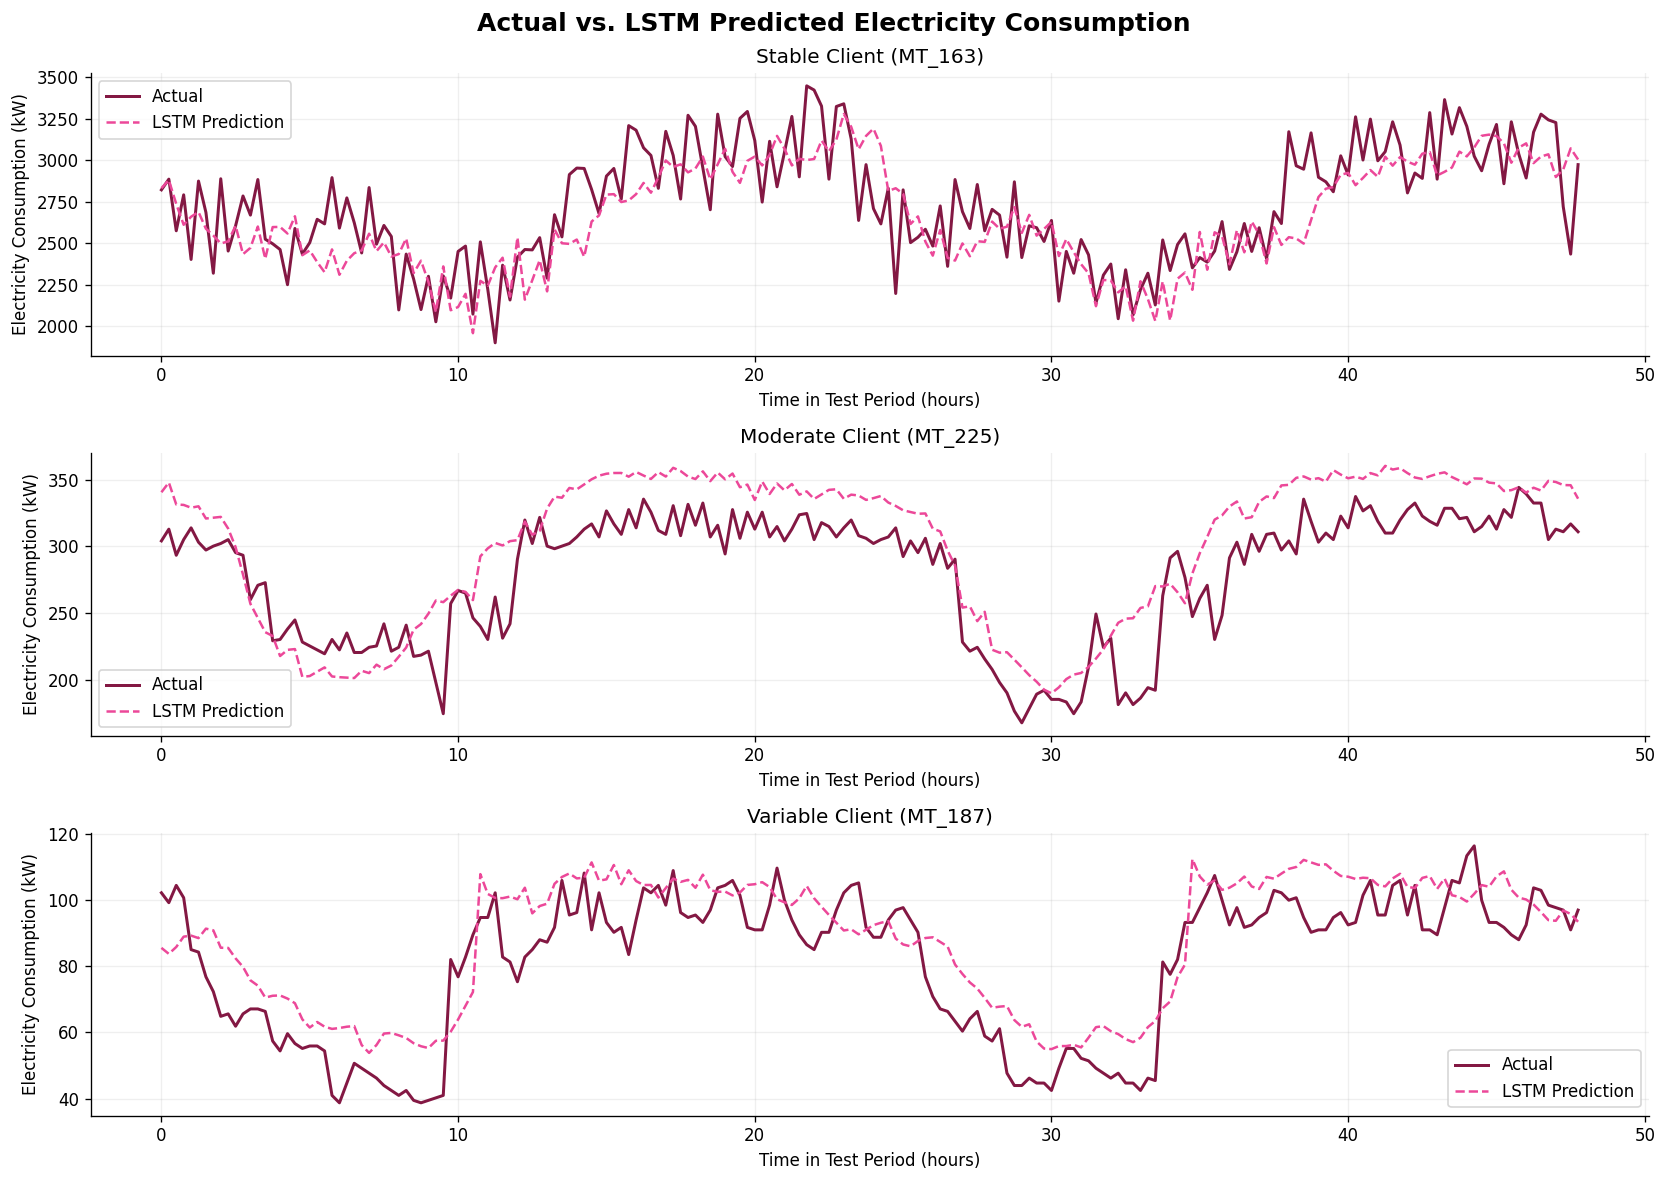

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

profiles = ["Stable", "Moderate", "Variable"]

for i, profile in enumerate(profiles):
    actual = predictions[profile]["Actual"]
    lstm_pred = predictions[profile]["LSTM"]

    n = min(192, len(actual))
    x = np.arange(n) * 0.25

    axes[i].plot(
        x, actual[:n],
        color="#831843",
        linewidth=1.8,
        label="Actual"
    )

    axes[i].plot(
        x, lstm_pred[:n],
        color="#EC4899",
        linewidth=1.5,
        linestyle="--",
        label="LSTM Prediction"
    )

    axes[i].set_title(
        f"{profile} Client ({datasets[profile]['client']})",
        fontsize=12
    )

    axes[i].set_xlabel("Time in Test Period (hours)")
    axes[i].set_ylabel("Electricity Consumption (kW)")
    axes[i].legend()
    axes[i].grid(alpha=0.2)

plt.suptitle(
    "Actual vs. LSTM Predicted Electricity Consumption",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("actual_vs_predicted.pdf", bbox_inches="tight")
plt.show()

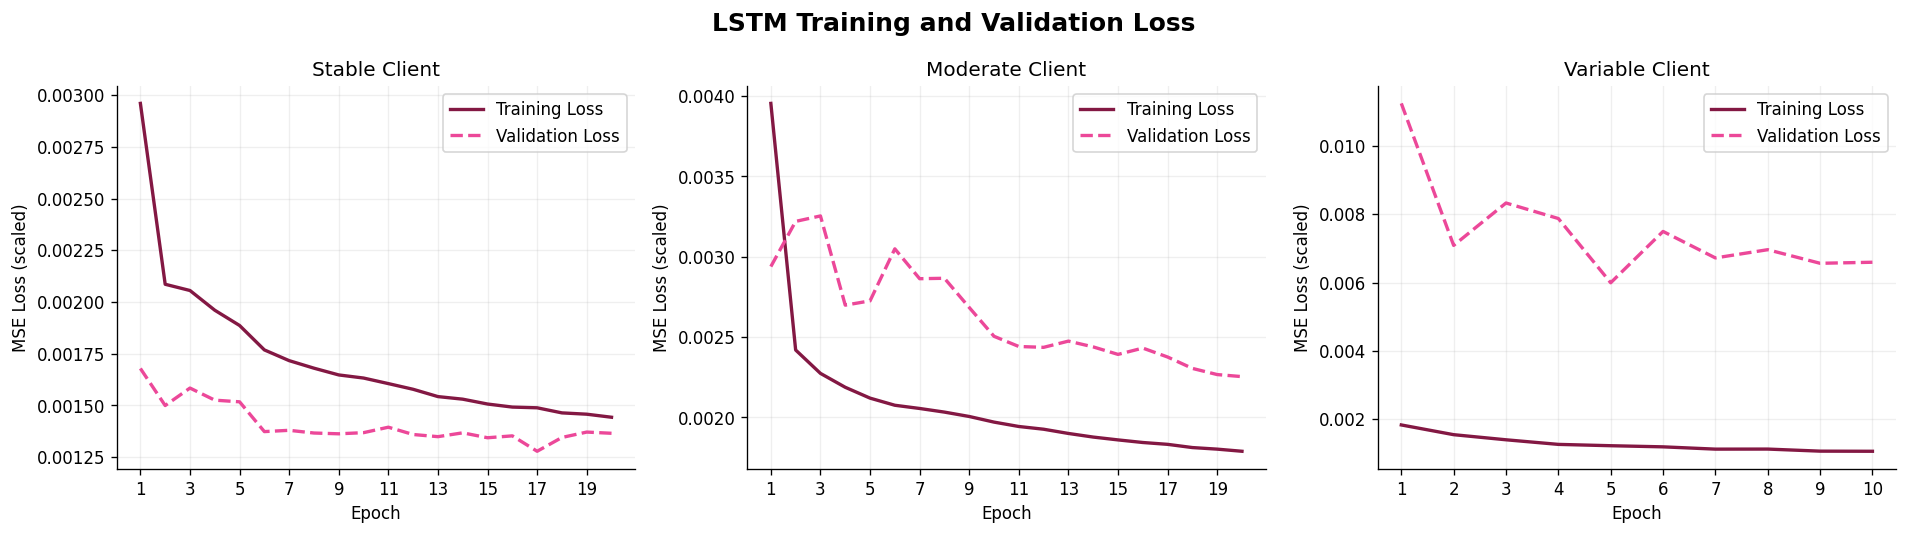

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, profile in enumerate(["Stable", "Moderate", "Variable"]):
    history = training_histories[profile]

    epochs = np.arange(1, len(history["loss"]) + 1)

    axes[i].plot(
        epochs,
        history["loss"],
        color="#831843",
        linewidth=2,
        label="Training Loss"
    )

    axes[i].plot(
        epochs,
        history["val_loss"],
        color="#EC4899",
        linewidth=2,
        linestyle="--",
        label="Validation Loss"
    )

    axes[i].set_title(f"{profile} Client")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE Loss (scaled)")
    axes[i].legend()
    axes[i].grid(alpha=0.2)
    axes[i].set_xticks(epochs[::max(1, len(epochs)//10)])

plt.suptitle(
    "LSTM Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("training_validation_loss.pdf", bbox_inches="tight")
plt.show()

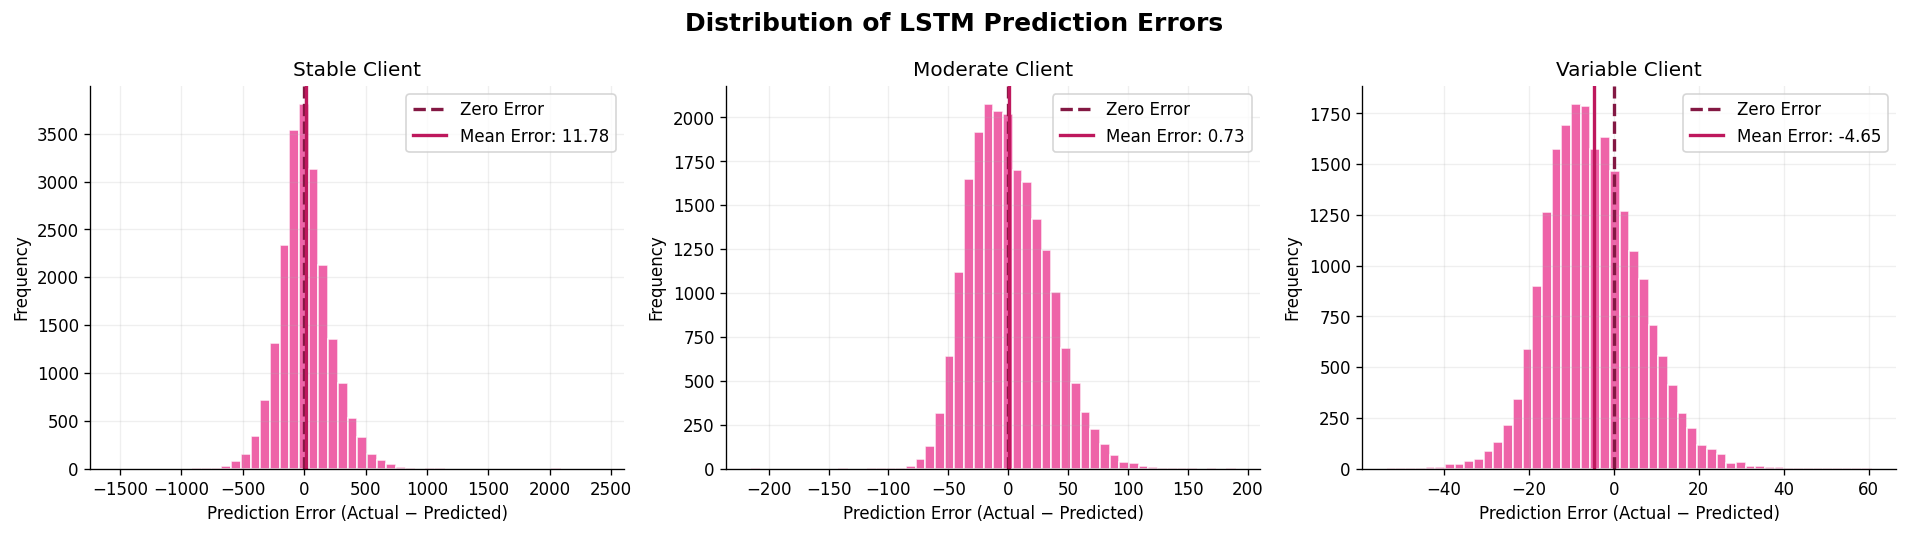

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, profile in enumerate(["Stable", "Moderate", "Variable"]):
    actual = predictions[profile]["Actual"]
    forecast = predictions[profile]["LSTM"]

    errors = actual - forecast

    axes[i].hist(
        errors,
        bins=50,
        color="#EC4899",
        edgecolor="white",
        alpha=0.85
    )

    axes[i].axvline(
        0,
        color="#831843",
        linestyle="--",
        linewidth=2,
        label="Zero Error"
    )

    axes[i].axvline(
        errors.mean(),
        color="#BE185D",
        linestyle="-",
        linewidth=2,
        label=f"Mean Error: {errors.mean():.2f}"
    )

    axes[i].set_title(f"{profile} Client")
    axes[i].set_xlabel("Prediction Error (Actual − Predicted)")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()
    axes[i].grid(axis="y", alpha=0.2)

plt.suptitle(
    "Distribution of LSTM Prediction Errors",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("prediction_errors.pdf", bbox_inches="tight")
plt.show()

In [25]:
import sys
import platform
import sklearn
import scipy
import matplotlib

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Operating System:", platform.platform())
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Random Seed:", SEED)

for profile in ["Stable", "Moderate", "Variable"]:
    print(
        profile,
        "| Epochs:", len(training_histories[profile]["loss"]),
        "| Training Time:", round(training_times[profile], 1), "seconds"
    )

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
Matplotlib: 3.10.0
Operating System: Linux-6.6.122+-x86_64-with-glibc2.39
GPU: []
Random Seed: 42
Stable | Epochs: 20 | Training Time: 2539.6 seconds
Moderate | Epochs: 20 | Training Time: 2531.8 seconds
Variable | Epochs: 10 | Training Time: 1268.6 seconds


In [27]:
dataset_summary = pd.DataFrame({
    "Parameter": [
        "Dataset",
        "Source",
        "Dataset period",
        "Original time points",
        "Clients in original dataset",
        "Selected clients",
        "Time interval",
        "Forecast horizon",
        "Input window",
        "Missing values",
        "Duplicate timestamps",
        "Removed observations",
        "Training observations",
        "Validation observations",
        "Testing observations",
        "Training windows per client",
        "Validation windows per client",
        "Testing windows per client"
    ],
    "Value": [
        "ElectricityLoadDiagrams20112014",
        "UCI Machine Learning Repository",
        "2011-01-01 00:15 to 2015-01-01 00:00",
        len(df),
        370,
        3,
        "15 minutes",
        "1 hour (4 steps)",
        "24 hours (96 steps)",
        0,
        0,
        0,
        98179,
        21038,
        21039,
        len(datasets["Stable"]["X_train"]),
        len(datasets["Stable"]["X_val"]),
        len(datasets["Stable"]["X_test"])
    ]
})

dataset_statistics = []

for profile, data in datasets.items():
    train_values = data["values"][:98179]

    dataset_statistics.append({
        "Profile": profile,
        "Client": data["client"],
        "Mean Consumption": np.mean(train_values),
        "Std Consumption": np.std(train_values),
        "Min Consumption": np.min(train_values),
        "Max Consumption": np.max(train_values)
    })

dataset_statistics_df = pd.DataFrame(dataset_statistics)

print("TABLE 1 — DATASET DESCRIPTION")
display(dataset_summary)

print("TARGET DISTRIBUTION — SELECTED CLIENTS")
display(dataset_statistics_df.round(3))

print("TABLE 2 — MODEL PERFORMANCE")
display(results_df.round(3))

print("TABLE 3 — STATISTICAL RESULTS")
display(statistical_df.round(4))

dataset_summary.to_csv("dataset_summary.csv", index=False)
dataset_statistics_df.to_csv("dataset_statistics.csv", index=False)
results_df.to_csv("model_results.csv", index=False)
statistical_df.to_csv("statistical_results.csv", index=False)

print("All tables saved successfully!")

TABLE 1 — DATASET DESCRIPTION


,Parameter,Value
0,Dataset,ElectricityLoadDiagrams20112014
1,Source,UCI Machine Learning Repository
2,Dataset period,2011-01-01 00:15 to 2015-01-01 00:00
3,Original time points,140256
4,Clients in original dataset,370
5,Selected clients,3
6,Time interval,15 minutes
7,Forecast horizon,1 hour (4 steps)
8,Input window,24 hours (96 steps)
9,Missing values,0


TARGET DISTRIBUTION — SELECTED CLIENTS


,Profile,Client,Mean Consumption,Std Consumption,Min Consumption,Max Consumption
0,Stable,MT_163,2403.456,384.924,0.000,4923.963
1,Moderate,MT_225,353.871,112.740,1.659,668.615
2,Variable,MT_187,32.999,44.296,0.000,167.785


TABLE 2 — MODEL PERFORMANCE


,Profile,Client,Model,MAE,RMSE,MAPE (%)
0,Moderate,MT_225,Gradient Boosting,24.246,31.609,9.200
1,Moderate,MT_225,LSTM,25.907,32.175,9.076
2,Moderate,MT_225,Persistence,25.457,37.314,9.387
3,Moderate,MT_225,Seasonal Naive,15.922,23.360,5.850
4,Stable,MT_163,Gradient Boosting,151.499,202.487,6.147
5,Stable,MT_163,LSTM,155.611,207.481,6.254
6,Stable,MT_163,Persistence,185.299,247.603,7.601
7,Stable,MT_163,Seasonal Naive,265.090,372.634,10.930
8,Variable,MT_187,Gradient Boosting,8.305,10.988,9.971
9,Variable,MT_187,LSTM,9.699,11.982,13.207


TABLE 3 — STATISTICAL RESULTS


,Profile,Baseline,LSTM MAE CI Lower,LSTM MAE CI Upper,DM Statistic,p-value
0,Stable,Persistence,149.3779,161.9714,-21.3315,0.0000
1,Stable,Seasonal Naive,149.3779,161.9714,-30.1709,0.0000
2,Stable,Gradient Boosting,149.3779,161.9714,4.9162,0.0000
3,Moderate,Persistence,24.8942,26.7861,-12.5255,0.0000
4,Moderate,Seasonal Naive,24.8942,26.7861,19.2412,0.0000
5,Moderate,Gradient Boosting,24.8942,26.7861,1.8926,0.0584
6,Variable,Persistence,9.4769,9.8571,-13.6383,0.0000
7,Variable,Seasonal Naive,9.4769,9.8571,3.0282,0.0025
8,Variable,Gradient Boosting,9.4769,9.8571,10.9327,0.0000


All tables saved successfully!
